# Recopilación de datos de NASA POWER

Este código accede a la API de NASA POWER para recopilar información de varias coordenadas a nivel global, permite graficar esta información en un plano, y exportar los datos recopilados a una base de datos en formato csv.

Se usan las siguientes librerías:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import csv
from time import sleep

## Recopilación de datos:
Se recopilan datos de la API de NASA POWER:

In [2]:
url_base = r"https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M,RH2M,PS,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_LW_DWN&community=RE&longitude={longitude}&latitude={latitude}&start={inicio}&end={fin}&format=csv&header=false"

puntos=[]
for x in range(-90,91,4):
    for y in range(-156,181,4): puntos.append((x,y))
print(len(puntos))

temperaturas = [] # °C
humedades = [] # %
presiones = [] # hPa
radiación_shortwave = [] # Wm^-2
radiación_longwave = [] # Wm^-2


for (lat, long) in puntos:
    url = url_base.format(longitude=long, latitude=lat, inicio = 2024, fin = 2024)
    df = pd.read_csv(url)

    radiación_longwave.append(df['ANN'][0])
    radiación_shortwave.append(df['ANN'][1])
    temperaturas.append(df['ANN'][4])
    humedades.append(df['ANN'][3])
    presiones.append(df['ANN'][2])
    print(len(temperaturas))

    sleep(0.005)

3910
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276

## Gráficos
Se genera usando matplotlib un diagramas de calor.

### Temperatura

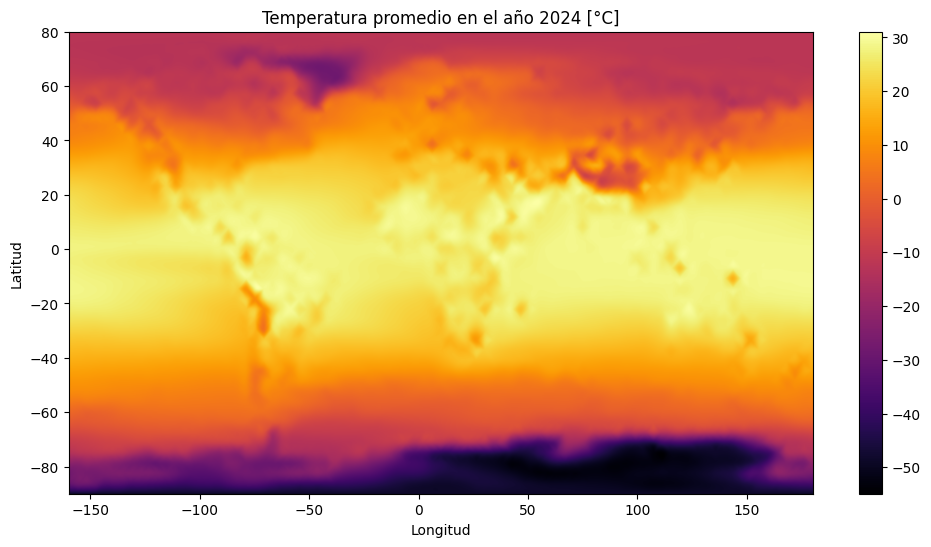

In [18]:
plt.rcParams['figure.figsize'] = [12,6]
plt.ylabel('Latitud')
plt.xlabel('Longitud')
plt.title('Temperatura promedio en el año 2024 [°C]')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-156:180:1700j, -90:90:1700j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), temperaturas, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(-160, 180, -90, 80), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()

plt.savefig('Temperatura.svg', format='svg')

### Humedad

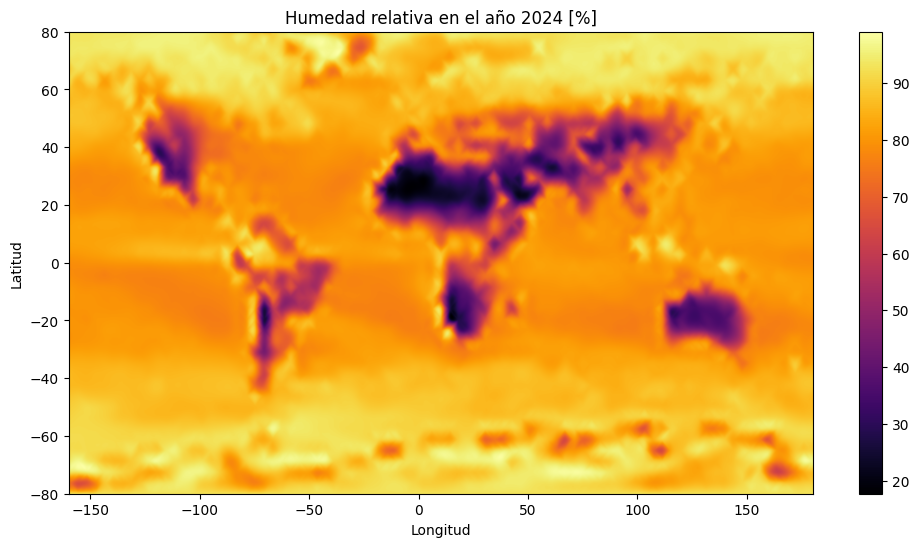

In [19]:
plt.rcParams['figure.figsize'] = [12,6]
plt.ylabel('Latitud')
plt.xlabel('Longitud')
plt.title('Humedad relativa en el año 2024 [%]')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-156:180:1700j, -90:80:1700j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), humedades, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(-160, 180, -80, 80), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()

plt.savefig('Humedad.svg', format='svg')

### Presión

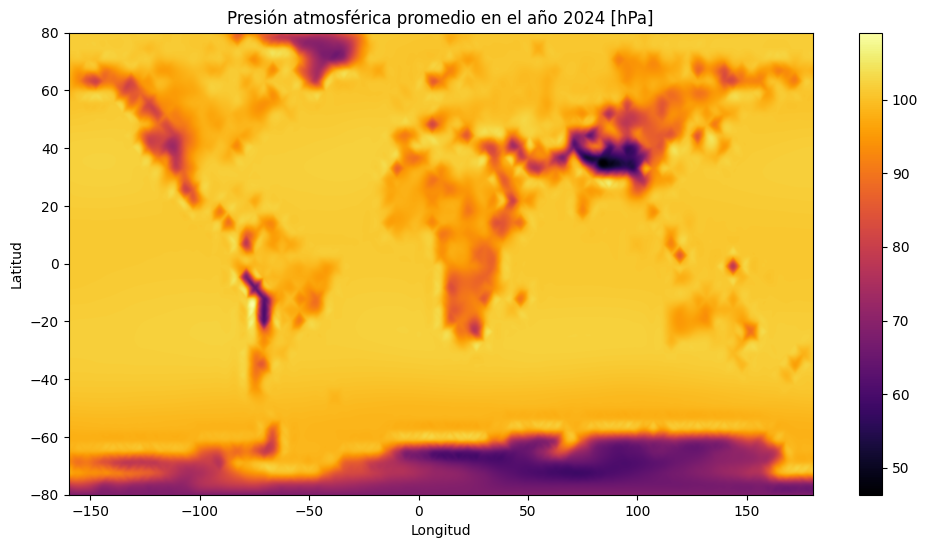

In [20]:
plt.rcParams['figure.figsize'] = [12,6]
plt.ylabel('Latitud')
plt.xlabel('Longitud')
plt.title('Presión atmosférica promedio en el año 2024 [hPa]')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-156:180:1700j, -90:80:1700j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), presiones, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(-160, 180, -80, 80), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()

plt.savefig('Presión.svg', format='svg')

### Radiación (longwave)

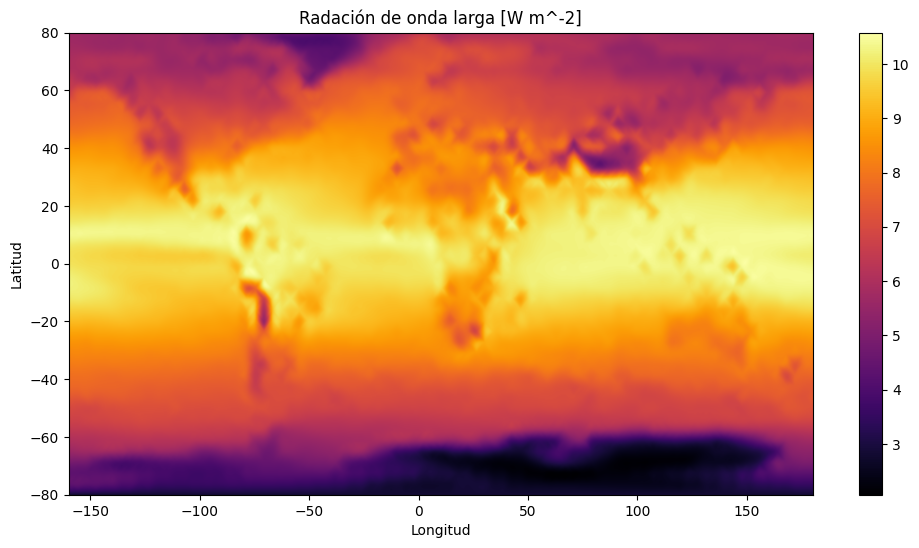

In [21]:
plt.ylabel('Latitud')
plt.xlabel('Longitud')
plt.title('Radación de onda larga [W m^-2]')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-156:180:1700j, -90:80:1700j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), radiación_longwave, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(-160, 180, -80, 80), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()

plt.savefig('longwave.svg', format='svg')

### Radiación (shortwave)

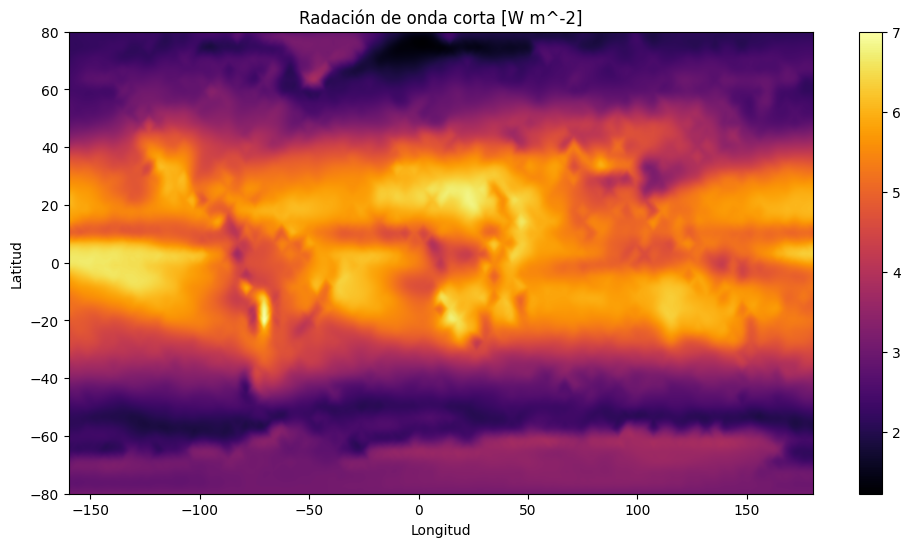

In [22]:
plt.ylabel('Latitud')
plt.xlabel('Longitud')
plt.title('Radación de onda corta [W m^-2]')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-156:180:1700j, -90:80:1700j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), radiación_shortwave, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(-160, 180, -80, 80), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()

plt.savefig('shortwave.svg', format='svg')

## Creación de archivo csv


In [8]:
nombre = "database.csv"

with open(nombre, 'w', newline='') as archivito:
    escritor = csv.writer(archivito)
    escritor.writerow(['Latitud', 'Longitud', 'Temperatura [°C]', 'Humedad relativa [%]', 'Presión [hPa]'])
    for i in range(len(puntos)):
        escritor.writerow([puntos[i][1], puntos[i][0], temperaturas[i], humedades[i], presiones[i]])

## Ejemplos de uso:

In [9]:
print('Ingrese el número que se adecúe a la restricción. Si no responde uno se asignará temperatura por defecto.')
print('1    Temperatura [°C]')
print('2    Humedad relativa [%]')
print('3    Presión atmosférica [hPa]')

num = int(input())
if num==2: ref = humedades
elif num==3: ref = presiones
else: ref = temperaturas

print('Ingrese valor de referencia: ')
buscando = float(input())

dif = [np.abs(i-buscando) for i in ref]

mín_index = dif.index(min(dif))

print(f'Las coordenadas ideales son: {puntos[mín_index]}')


plt.ylabel('Latitud')
plt.xlabel('Longitud')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-156:180:100j, -90:80:100j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), ref, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(-160, 180, -80, 80), origin='lower', cmap='inferno', aspect='auto')
plt.scatter([puntos[mín_index][1]], puntos[mín_index][0])
plt.colorbar()

Ingrese el número que se adecúe a la restricción. Si no responde uno se asignará temperatura por defecto.
1    Temperatura [°C]
2    Humedad relativa [%]
3    Presión atmosférica [hPa]


ValueError: invalid literal for int() with base 10: ''